### 선형 회귀 실습 문제

# Tips Dataset
: 레스토랑의 총 식사 금액을 이용해 손님이 지불할 팁 금액을 예측하는 선형 회귀 모델 구현.

In [2]:
import pandas as pd  
import numpy as np 
import matplotlib.pyplot as plt 
import torch
from torch import nn,optim
from torch.utils.data import TensorDataset,DataLoader

torch.manual_seed(42)


#### Step1. 데이터 불러오기 및 전처리

**사용 데이터: Tips Dataset**

- 데이터: 244개
- 입력 특징: 1개 (총 식사 금액 (`total_bill`))
- 정답: 팁 금액(`tip`)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `total_bill` | 총 식사 금액 | 식사에 청구된 총 금액 |
| `tip` | 팁 금액 | 종업원에게 지불한 팁 |
| `sex` | 성별 | 계산한 손님의 성별 |
| `smoker` | 흡연 여부 | 흡연자 여부 |
| `day` | 요일 | 식사한 요일 |
| `time` | 식사 시간 | Lunch 또는 Dinner |
| `size` | 인원수 | 테이블의 손님 수 |

**실습 조건**
- 입력값(X): `total_bill`
- 정답(y): `tip`
- 결측치가 있는지 확인하고, 필요한 경우 처리한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 입력값은 학습 데이터의 평균과 표준편차를 이용해 표준화한다.
- `total_bill`과 `tip`의 관계를 산점도로 먼저 확인한다.

In [5]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)
print(df)
# 이번 실습에 필요한 두 열만 사용
df = df[["total_bill", "tip"]].dropna().copy()
print(df)

     total_bill   tip     sex smoker   day    time  size
0         16.99  1.01  Female     No   Sun  Dinner     2
1         10.34  1.66    Male     No   Sun  Dinner     3
2         21.01  3.50    Male     No   Sun  Dinner     3
3         23.68  3.31    Male     No   Sun  Dinner     2
4         24.59  3.61  Female     No   Sun  Dinner     4
..          ...   ...     ...    ...   ...     ...   ...
239       29.03  5.92    Male     No   Sat  Dinner     3
240       27.18  2.00  Female    Yes   Sat  Dinner     2
241       22.67  2.00    Male    Yes   Sat  Dinner     2
242       17.82  1.75    Male     No   Sat  Dinner     2
243       18.78  3.00  Female     No  Thur  Dinner     2

[244 rows x 7 columns]
     total_bill   tip
0         16.99  1.01
1         10.34  1.66
2         21.01  3.50
3         23.68  3.31
4         24.59  3.61
..          ...   ...
239       29.03  5.92
240       27.18  2.00
241       22.67  2.00
242       17.82  1.75
243       18.78  3.00

[244 rows x 2 columns]


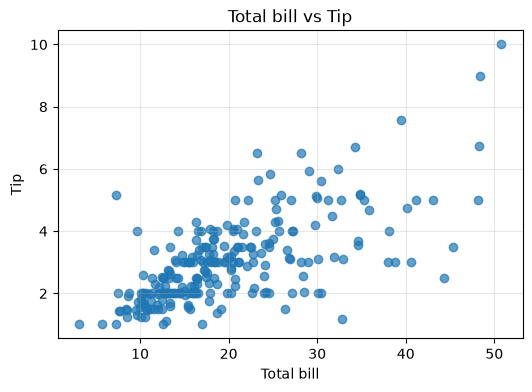

In [6]:
plt.figure(figsize=(6, 4))
plt.scatter(df["total_bill"], df["tip"], alpha=0.7)
plt.xlabel("Total bill")
plt.ylabel("Tip")
plt.title("Total bill vs Tip")
plt.grid(alpha=0.3)
plt.show()

In [21]:
x = torch.tensor(df[["total_bill"]].values, dtype=torch.float32)
y = torch.tensor(df[["tip"]].values, dtype=torch.float32)

In [16]:
# 학습 데이터와 테스트 데이터 분리(8:2)
indices = torch.randperm(len(x))
train_size = int(len(x) * 0.8)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

x_train = x[train_indices]
x_test = x[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

# 데이터 표준화
mean = x_train.mean()
std = x_train.std()

x_train_scaled = (x_train - mean) / std
x_test_scaled = (x_test - mean) / std

print('x_train :', x_train_scaled.shape)
print('y_train :', y_train.shape)
print('x_test :', x_test_scaled.shape)
print('y_test :', y_test.shape)

x_train : (195, 1)
y_train : (195, 1)
x_test : (49, 1)
y_test : (49, 1)


In [24]:
print(type(x_train_scaled))
print(type(y_train))
print(type(x_test_scaled))
print(type(y_test))

x_train_scaled = torch.tensor(x_train_scaled, dtype=torch.float32)
x_test_scaled = torch.tensor(x_test_scaled, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [25]:
BATCH_SIZE = 32

train_DS = TensorDataset(x_train_scaled, y_train)
test_DS = TensorDataset(x_test_scaled, y_test)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle=False)

N = len(train_DL.dataset)
print('학습데이터 개수 :', N)

학습데이터 개수 : 195


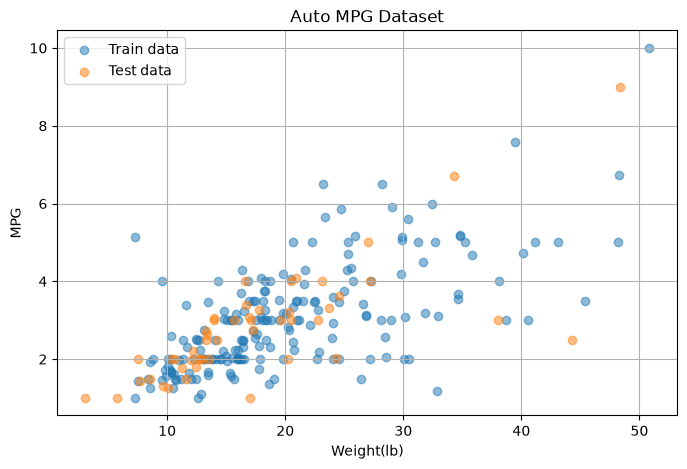

In [10]:
plt.figure(figsize=(8,5))

plt.scatter(x_train, y_train, alpha=0.5, label='Train data')
plt.scatter(x_test, y_test, alpha=0.5, label='Test data')

plt.xlabel('Weight(lb)')
plt.ylabel('MPG')
plt.title('Auto MPG Dataset')
plt.legend()
plt.grid(True)

#### Step2. 모델 만들기

- 입력 노드: 1개 (`total_bill`)
- 출력 노드: 1개 (`tip`)
- 활성화 함수: 사용하지 않음
- 모델: `nn.Linear`

In [11]:
model = nn.Linear(1,1)
print(model)

Linear(in_features=1, out_features=1, bias=True)


#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: MSELoss
- 학습률(LR): 0.01부터 시작
- Epoch: 200
- Batch size: 32

In [39]:
lr = 0.01
epoch = 200

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=1e-1)

loss_history = []

model.train()
for ep in range(epoch):
    rloss = 0

    for x_batch, y_batch in train_DL:
        y_hat = model(x_batch)

        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    loss_e = rloss / len(train_DL.dataset)
    loss_history.append(loss_e)

    if ep % 10 == 0:
        print(f'{ep+1},{loss_e:.4f}')

1,0.9991
11,1.0515
21,1.0583
31,1.0095
41,1.0182
51,1.0164
61,1.0147
71,1.0024
81,1.0128
91,1.0184
101,1.0965
111,1.0098
121,1.0272
131,0.9988
141,1.0019
151,1.0203
161,1.0148
171,1.0229
181,1.0599
191,1.0038


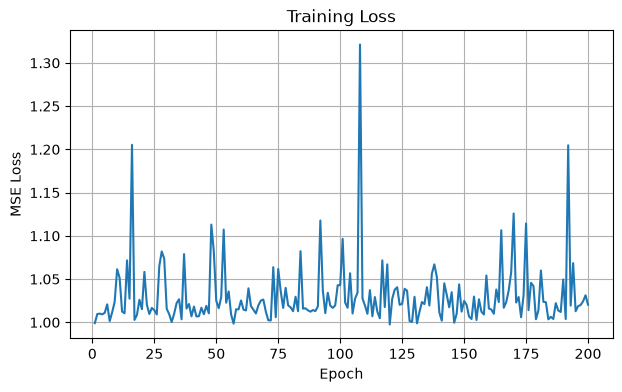

In [41]:
plt.figure(figsize=(7,4))

plt.plot(range(1, len(loss_history)+1), loss_history)

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss')
plt.grid()

plt.show()

#### Step4. 모델 테스트하기


In [42]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test_scaled)

test_loss = criterion(y_pred, y_test).item()  # MSELoss 
test_mae = torch.mean(torch.abs(y_pred - y_test)).item()  # MAELoss
test_rmse = np.sqrt(test_loss)  # MSE에 제곱근을 씌워 원래 데이터와 동일한 단위로 해석

print(f'Test MSE : {test_loss:.3f}')
print(f'Test MAE : {test_mae:.3f} MPG')
print(f'Test RMSE : {test_rmse:.3f} MPG')


Test MSE : 1.286
Test MAE : 0.862 MPG
Test RMSE : 1.134 MPG


#### Step5. 테스트 결과 시각화

**문제**
- 첫 번째 그래프: 테스트 데이터의 실제 산점도와 모델의 예측 회귀선을 함께 표시.
- 두 번째 그래프: 실제 팁 금액을 x축, 예측 팁 금액을 y축으로 하는 산점도를 작성.
- 두 번째 그래프에 완벽한 예측을 나타내는 기준선(y=x)을 추가.
- 그래프의 축 이름과 제목을 적절히 표시.

In [47]:
print(type(x_test))
print(type(x_test_scaled))
print(type(y_test))

x_test= x_test[sort_idx]

<class 'numpy.ndarray'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>


NameError: name 'sort_idx' is not defined

In [48]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test_scaled)

# 무게를 기준을 정렬을 하여 회귀선을 표시
# argsort() : 정렬된 순서에 해당하는 인덱스 반환하는 함수
sort_idx = torch.argsort(x_test.squeeze())
x_test_sorted = x_test[sort_idx]
x_test_scaled_sorted = x_test_scaled[sort_idx]
y_test_sorted = y_test[sort_idx]
print(type(x_test))
print(type(x_test_scaled))
print(type(y_test))

with torch.no_grad():
    y_pred_sorted = model(x_test_scaled_sorted)

fig, axes = plt.subplots(1, 2, figsize=(13,5))

# 실제테스트 데이터와 예측 회귀선
axes[0].scatter(x_test.numpy(), y_test.numpy(), 
                alpha = 0.6, label='Actual test data')
axes[0].plot(x_test_sorted.numpy(), y_pred_sorted.numpy(), 
            linewidth=2, label='Predicted regression line')
axes[0].set_xlabel('Weight(lb)')
axes[0].set_ylabel('MPG')
axes[0].set_title('Actual Data vs Regression Line')
axes[0].legend()
axes[0].grid(True)

# 테스트 실제값과 예측값 비교
axes[1].scatter(y_test.numpy(), y_pred.numpy(), alpha=0.6)
min_val = min(y_test.min().item(), y_pred.min().item())
max_val = max(y_test.max().item(), y_pred.max().item())
axes[1].plot([min_val, max_val], [min_val, max_val], 
                linestyle='--', label='Perfect prediction')
axes[1].set_xlabel('Actual MPG')
axes[1].set_ylabel('Predicted MPG')
axes[1].set_title('Actual vs Predicted')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

TypeError: argsort(): argument 'input' (position 1) must be Tensor, not numpy.ndarray

#### STEP 6. 파라미터 개수 확인